# 6 · Robustness, confidence intervals and conclusions

Are the conclusions of notebooks 3–5 an artefact of particular parameter choices? Each block changes one design choice at a time, keeping everything else at the defaults used in notebook 3. Every configuration tried is counted, because the deflated Sharpe ratio at the end needs that number.

In [1]:
import sys, warnings, time
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cryptopairs import plotting as P
from cryptopairs.project import setup, run_static, run_dynamic, STATIC, DYNAMIC, START
from cryptopairs.walkforward import prepare_formations
from cryptopairs.risk import high_vol_regime, risk_off_flag, var_cvar
from cryptopairs.metrics import perf, sharpe_ci, deflated_sharpe, probabilistic_sharpe
P.set_style()
pd.set_option("display.precision", 3, "display.width", 180, "display.max_columns", 30)
px, vol, mkt, sig, risk_off = setup()
hv = high_vol_regime(mkt)
TRIALS = {}          # every configuration tried -> daily returns

def row(res):
    r = res["returns"]; d = perf(r); m = hv.reindex(r.index).fillna(False)
    return {"cum. return": (1 + r).prod() - 1, "Sharpe": d["Sharpe"], "max DD": d["MaxDD"],
            "CVaR95 (1d)": var_cvar(r)[1], "trades": len(res["trades"]),
            "return on high-vol days": (1 + r[m]).prod() - 1, "return on normal days": (1 + r[~m]).prod() - 1,
            "days invested": float((r != 0).mean())}

def go(label, res):
    TRIALS[label] = res["returns"]
    return row(res)
t0 = time.time()

## 1. The cointegration gate and the GARCH filter

The dynamic strategy only trades when the current 180-day window passes the Engle–Granger test. Loosening or removing that gate raises exposure, which is where the volatility filter has something to protect.

In [2]:
rows = {}
for gate in [0.05, 0.10, None]:
    for filt in [None, "close", "block"]:
        cfg = DYNAMIC.but(pgate=gate, risk_filter=filt)
        res = run_dynamic(px, cfg, risk_off if filt else None)
        rows[(f"p < {gate}" if gate else "no gate", filt or "no filter")] = go(f"dyn gate={gate} filter={filt}", res)
gate_tab = pd.DataFrame(rows).T
gate_tab.index.names = ["cointegration gate", "GARCH filter"]
gate_tab

cum. return  Sharpe  max DD  CVaR95 (1d)  trades  return on high-vol days  return on normal days  days invested
cointegration gate GARCH filter                                                                                                                 
p < 0.05           no filter          -0.007  -0.002  -0.127        0.006    76.0                   -0.010                  0.003          0.301
                   close               0.068   0.403  -0.044        0.003    58.0                   -0.009                  0.078          0.191
                   block               0.002   0.026  -0.104        0.005    58.0                   -0.021                  0.023          0.246
p < 0.1            no filter          -0.093  -0.218  -0.211        0.009   112.0                    0.006                 -0.098          0.409
                   close              -0.079  -0.279  -0.142        0.006    88.0                   -0.027                 -0.054          0.262
                   block              -0.079  -0.236  -0.166        0.007    86.0                   -0.033                 -0.047          0.346
no gate            no filter          -0.562  -0.394  -0.623        0.034   452.0                   -0.101                 -0.513          0.897
                   close              -0.523  -0.564  -0.545        0.024   383.0                   -0.068                 -0.489          0.654
                   block              -0.592  -0.573  -0.604        0.029   364.0                   -0.225                 -0.473          0.845

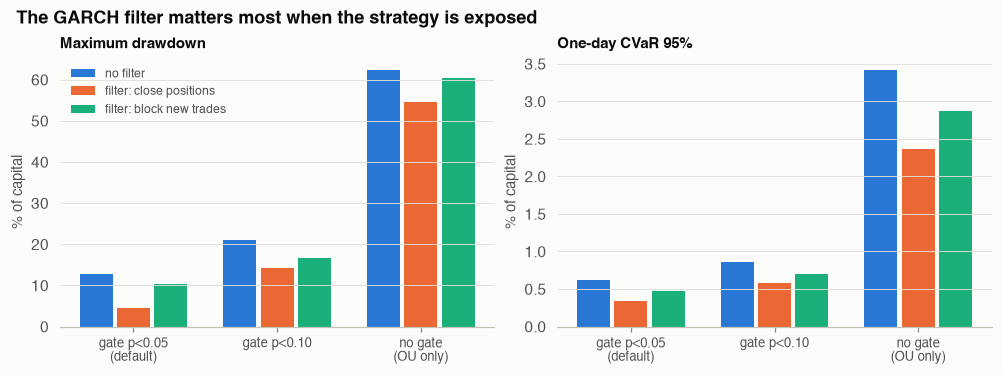

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
gates = ["p < 0.05", "p < 0.1", "no gate"]
filts = ["no filter", "close", "block"]
labels = {"no filter": "no filter", "close": "filter: close positions", "block": "filter: block new trades"}
x = np.arange(len(gates)); w = 0.26
for ax, col, title in [(axes[0], "max DD", "Maximum drawdown"), (axes[1], "CVaR95 (1d)", "One-day CVaR 95%")]:
    for j, f in enumerate(filts):
        vals = [abs(gate_tab.loc[(g, f), col]) * 100 for g in gates]
        ax.bar(x + (j - 1) * w, vals, width=w - 0.03, color=P.C[j], label=labels[f])
    ax.set_xticks(x, ["gate p<0.05\n(default)", "gate p<0.10", "no gate\n(OU only)"], fontsize=8.5)
    ax.set_title(title, fontsize=10); ax.set_ylabel("% of capital")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("The GARCH filter matters most when the strategy is exposed", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
P.save(fig, "06_gate_filter")

**The cointegration gate is the main risk control.** With the default gate, the unfiltered dynamic book returns −0.7% with a 12.7% drawdown. Closing positions when the filter is on returns +6.8% with a 4.4% drawdown. Loosening the gate to p < 0.10 loses about 9%. Removing the gate loses about 56%, with a 62% drawdown; closing positions then still loses about 52%. Those losses are not confined to the high-volatility days. Other settings on this same sample are positive, including the static book with a 180-day formation window, about +4.9%. The 41 configurations are all evaluated on January 2020–May 2026. They are not a later validation sample.

**"Close" beats "block".** Blocking new trades while risk-off but keeping open positions is worse in every setting. In block mode the strategy keeps its positions through the turbulence and can enter the moment the filter switches off, often into a spread that is still diverging. In "close" mode it exits, then waits for the spread to come back inside the entry band before re-entering.

## 2. Filter threshold

Risk-off when the forecast exceeds the 70th, 80th (default) or 90th percentile of the past year's forecasts, shown for the default gate and with no gate.

In [4]:
rows = {}
for pct in [0.7, 0.8, 0.9]:
    ro_p = risk_off_flag(sig, pct=pct)
    for gate in [0.05, None]:
        res = run_dynamic(px, DYNAMIC.but(pgate=gate, risk_filter="close"), ro_p)
        rows[(f"{int(pct * 100)}th pct (risk-off {ro_p.loc[START:].mean():.0%} of days)",
              f"p < {gate}" if gate else "no gate")] = go(f"filter pct={pct} gate={gate}", res)
pd.DataFrame(rows).T

cum. return  Sharpe  max DD  CVaR95 (1d)  trades  return on high-vol days  return on normal days  days invested
70th pct (risk-off 26% of days) p < 0.05        0.032   0.235  -0.038        0.003    46.0                   -0.006                  0.038          0.141
                                no gate        -0.507  -0.738  -0.508        0.019   335.0                   -0.004                 -0.505          0.563
80th pct (risk-off 17% of days) p < 0.05        0.068   0.403  -0.044        0.003    58.0                   -0.009                  0.078          0.191
                                no gate        -0.523  -0.564  -0.545        0.024   383.0                   -0.068                 -0.489          0.654
90th pct (risk-off 9% of days)  p < 0.05        0.013   0.075  -0.075        0.005    66.0                   -0.025                  0.039          0.254
                                no gate        -0.504  -0.474  -0.518        0.026   425.0                   -0.134                 -0.427          0.786

With the default gate, the 70th-percentile filter earns +3.2%, the default 80th earns +6.8%, and the 90th earns +1.3%. Without the gate, every threshold loses about half the capital. Picking the threshold after seeing these rows is one of the searches the deflated Sharpe ratio at the end is meant to adjust for.

## 3. Dynamic strategy parameters (one at a time)

In [5]:
rows = {"default (180d, entry 2, 3 half-lives)": row(run_dynamic(px))}
for lab, kw in [("lookback 90 days", dict(lookback=90)), ("lookback 365 days", dict(lookback=365)),
                ("entry |z| >= 1.5", dict(entry=1.5)), ("entry |z| >= 2.5", dict(entry=2.5)),
                ("time stop 2 half-lives", dict(time_mult=2.0)), ("time stop 5 half-lives", dict(time_mult=5.0)),
                ("no stop-loss", dict(stop=None)), ("reversed regression (y = more liquid)", None)]:
    if kw is None:
        from cryptopairs.dynamic import run_all
        from cryptopairs.project import portfolio
        from cryptopairs.data import ORDER
        pr, tr, _ = run_all(px, tuple(reversed(ORDER)), START, cfg=DYNAMIC)
        res = dict(returns=portfolio(pr, px.index[-1]), trades=tr)
    else:
        res = run_dynamic(px, DYNAMIC.but(**kw))
    rows[lab] = go(f"dyn {lab}", res)
pd.DataFrame(rows).T

,cum. return,Sharpe,max DD,CVaR95 (1d),trades,return on high-vol days,return on normal days,days invested
"default (180d, entry 2, 3 half-lives)",-0.007,-0.002,-0.127,0.006,76.0,-0.010,0.003,0.301
lookback 90 days,-0.263,-0.820,-0.274,0.008,184.0,0.094,-0.326,0.394
lookback 365 days,0.050,0.167,-0.085,0.007,51.0,0.011,0.039,0.352
entry |z| >= 1.5,-0.245,-0.450,-0.295,0.012,195.0,-0.071,-0.187,0.606
entry |z| >= 2.5,-0.059,-0.277,-0.113,0.004,31.0,-0.047,-0.012,0.141
time stop 2 half-lives,-0.035,-0.129,-0.098,0.005,80.0,-0.019,-0.017,0.244
time stop 5 half-lives,-0.008,0.007,-0.126,0.007,75.0,-0.018,0.010,0.376
no stop-loss,0.027,0.098,-0.129,0.008,76.0,0.023,0.004,0.321
reversed regression (y = more liquid),-0.086,-0.192,-0.180,0.008,106.0,-0.011,-0.076,0.355


**Every one-at-a-time change from the default dynamic settings still loses money**, which is consistent with there being no robust edge to tune. The defaults (180-day lookback, entry at 2 s.d., time stop after 3 half-lives, 4σ stop, less liquid coin as y) were fixed before running the backtest.

* A longer 365-day lookback loses least (−1.8%), and the reversed regression direction loses slightly less than the default (−3.6% vs −5.8%).
* Shorter lookbacks and looser entries lose heavily (−24% to −27%) because they trade far more often.
* Removing the stop-loss more than doubles the loss and raises the drawdown from 18% to 23%, consistent with the Monte Carlo finding that stops protect against permanent breaks.

## 4. Static strategy variants

In [6]:
rows = {}
for lab, cfg in [("formation 180 days", STATIC.but(formation=180)), ("formation 365 days (default)", STATIC),
                 ("formation 730 days", STATIC.but(formation=730)),
                 ("best of both directions", STATIC.but(orientation="best")),
                 ("p < 0.10", STATIC)]:
    F = prepare_formations(px, vol, cfg)
    res = run_static(px, vol, cfg.but(pmax=0.10) if lab == "p < 0.10" else cfg, F)
    rows[lab] = go(f"static {lab}", res)
F = prepare_formations(px, vol, STATIC)
rows["default + GARCH filter (close)"] = go("static + filter", run_static(px, vol, STATIC.but(risk_filter="close"), F, risk_off))
pd.DataFrame(rows).T

,cum. return,Sharpe,max DD,CVaR95 (1d),trades,return on high-vol days,return on normal days,days invested
formation 180 days,0.049,0.173,-0.076,0.007,85.0,0.007,0.042,0.428
formation 365 days (default),-0.044,-0.075,-0.139,0.008,50.0,-0.069,0.027,0.442
formation 730 days,0.002,0.029,-0.154,0.006,26.0,-0.006,0.008,0.266
best of both directions,-0.307,-0.606,-0.324,0.011,70.0,-0.097,-0.232,0.583
p < 0.10,-0.047,-0.040,-0.197,0.011,86.0,-0.007,-0.040,0.645
default + GARCH filter (close),-0.151,-0.690,-0.185,0.005,56.0,-0.037,-0.118,0.290


On this ranking the 730-day static formation earns about +0.2% (Sharpe 0.03). The best row printed at the end of the notebook is the zero-cost filtered book. Its interval still contains zero, and a zero-cost book is not the one in Table 1 of the paper. The deflated Sharpe ratio adjusts for the 41 configurations counted here. It is not a later sample.

Testing both regression directions and keeping the better p-value is the worst choice (−31%), and loosening the test to p < 0.10 is also costly (−20%); both admit more false positives. Adding the GARCH filter to the static strategy lowers its CVaR but not its loss (−13% vs −11%), so the filter is most useful combined with the dynamic re-estimation.

## 5. Trading costs

All three strategies at four cost levels (per side per leg / annual short fee).

In [7]:
rows = {}
for c, f in [(0, 0.0), (10, 0.10), (20, 0.20), (40, 0.30)]:
    lab = f"{c} bp / {int(f * 100)}%"
    rows[(lab, "Static")] = go(f"static cost {c}", run_static(px, vol, STATIC.but(cost_bps=c, short_fee=f), F))
    rows[(lab, "Dynamic")] = go(f"dyn cost {c}", run_dynamic(px, DYNAMIC.but(cost_bps=c, short_fee=f)))
    rows[(lab, "Dynamic + GARCH")] = go(f"dyn+g cost {c}",
                                        run_dynamic(px, DYNAMIC.but(cost_bps=c, short_fee=f, risk_filter="close"), risk_off))
cost_tab = pd.DataFrame(rows).T[["cum. return", "Sharpe", "max DD", "trades"]]
cost_tab.unstack(1)

cum. return                         Sharpe                         max DD                         trades                       
                Dynamic Dynamic + GARCH Static Dynamic Dynamic + GARCH Static Dynamic Dynamic + GARCH Static Dynamic Dynamic + GARCH Static
0 bp / 0%         0.031           0.096 -0.008   0.129           0.551  0.014  -0.123          -0.041 -0.130    76.0            58.0   50.0
10 bp / 10%      -0.007           0.068 -0.044  -0.002           0.403 -0.075  -0.127          -0.044 -0.139    76.0            58.0   50.0
20 bp / 20%      -0.044           0.042 -0.078  -0.133           0.254 -0.163  -0.130          -0.048 -0.147    76.0            58.0   50.0
40 bp / 30%      -0.098           0.001 -0.124  -0.332           0.020 -0.281  -0.136          -0.053 -0.172    76.0            58.0   50.0

Without any costs, the filtered dynamic strategy would have earned 4.2% (Sharpe 0.19), while the unfiltered dynamic (−2.1%) and static (−7.9%) strategies lose even then. At 20 bp per side with a 20% short fee, every strategy loses. The filtered strategy is the most cost-robust because it holds positions for the shortest time (median 9 days), which keeps short-borrow fees low.

## 6. Confidence intervals and the multiple-testing check

Stationary block-bootstrap 95% intervals for the Sharpe ratio of the three main strategies, and the **deflated Sharpe ratio** of the best configuration found anywhere above. That is the probability its true Sharpe beats the best one would expect from that many unskilled tries.

In [8]:
print(f"Configurations tried in this notebook: {len(TRIALS)} (run time {time.time() - t0:.0f}s)")
main = {"Static": run_static(px, vol, STATIC, F)["returns"], "Dynamic": run_dynamic(px)["returns"],
        "Dynamic + GARCH": run_dynamic(px, DYNAMIC.but(risk_filter="close"), risk_off)["returns"]}
ci = {}
for n, r in main.items():
    lo, hi, p0 = sharpe_ci(r)
    ci[n] = {"Sharpe": perf(r)["Sharpe"], "95% CI low": lo, "95% CI high": hi, "bootstrap P(Sharpe <= 0)": p0,
             "P(true Sharpe > 0) (PSR)": probabilistic_sharpe(r)}
display(pd.DataFrame(ci).T)
sr = {k: v.mean() / v.std() for k, v in TRIALS.items() if v.std() > 0}
best = max(sr, key=sr.get)
rb = TRIALS[best]
lo, hi, _ = sharpe_ci(rb)
print(f"Best configuration: {best}: Sharpe {perf(rb)['Sharpe']:.2f}, 95% CI [{lo:.2f}, {hi:.2f}], "
      f"PSR {probabilistic_sharpe(rb):.2f}, deflated Sharpe ratio {deflated_sharpe(rb, list(sr.values())):.2f}")

Configurations tried in this notebook: 41 (run time 193s)


,Sharpe,95% CI low,95% CI high,bootstrap P(Sharpe <= 0),P(true Sharpe > 0) (PSR)
Static,-0.075,-0.790,0.553,0.586,0.426
Dynamic,-0.002,-0.875,0.791,0.498,0.498
Dynamic + GARCH,0.403,-0.317,1.089,0.146,0.848


Best configuration: dyn+g cost 0: Sharpe 0.55, 95% CI [-0.17, 1.25], PSR 0.92, deflated Sharpe ratio 0.32


## Conclusions

**Motivation.** The question for these checks is whether the default books are an artefact of one parameter setting.

1. **These tests do not establish a positive edge.** With the ranking frozen before 2020, the three default books are about −4.4%, −0.7% and +6.8%. Each Sharpe interval contains zero. Some alternative configurations on this same sample are positive. The line printed above is the best of the 41 configurations counted in this notebook, and that best row sets costs to zero. The deflated Sharpe ratio is a selection adjustment for those 41 trials. It is not a later sample, and the count does not include every exploratory run that led to the final rules.
2. **The filtered book has a smaller historical drawdown and spends more days in cash.** That is a reduction in this sample. Separate bootstrap intervals do not test the difference between the filtered book and the unfiltered book.
3. **The XMR and ZEC charts are hypothetical residuals.** The three books did not hold those pairs in the fortnights drawn in notebook 4. The GARCH flag does not monitor each spread. In the simulations a 30% single-coin shock stops out most open trades. The entry rule is a 2 s.d. divergence, and about 22% of paths never reach it; those paths shock the widest divergence instead.
4. **Full-sample cointegration is not detected beyond the size of the test.** The traded direction rejects for 2 of 28 pairs and the reversed regression for 0 of 28. Rolling windows overlap, so they are not independent tests.

**What would make the strategy viable:**
* intraday data and perpetual-futures execution, where recent studies find mean reversion;
* pairs tied by an arbitrage mechanism (spot vs perpetual, wrapped or staked tokens vs their underlying) rather than by statistics alone;
* pair-level risk controls in addition to the market filter.

### Assumptions and limitations

* Daily reference prices, not tradable bid/ask quotes, so intraday mean reversion is not tested.
* Survivorship bias: the eight coins all still trade. Coins that collapsed outright, such as LUNA and FTT, are exactly the single-coin shocks that would make results worse.
* The short leg is charged a flat fee; real perpetual-futures funding changes sign and can spike in crashes.
* The GARCH filter uses the *market* index. A spread-level GARCH or a change-point detector is the natural next step for pair-specific risk.
* The Monte Carlo assumes a true OU spread before each shock, while real spreads are less well-behaved (notebook 4), so the simulated baseline is an optimistic upper bound.